In [1]:
import numpy as np
import pandas as pd
from WindowFunctions import val_df2windows, make_windows

In [5]:
training_clustered = pd.read_csv(f"C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/training_clustered_normalized.csv").drop(columns=['Unnamed: 0'])
training = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/training_clustered.csv").drop(columns=['Unnamed: 0'])

Val_X_df = pd.read_csv(f"C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/Val_X_clustered.csv").drop(columns=['Unnamed: 0'])
Val_y_df = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/Val_y.csv").drop(columns=['Unnamed: 0'])

Val_X_df_norm = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/Val_X_normalized_cluster.csv")
Val_y_df_norm = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/Val_y_normalized.csv")


In [7]:
training_clustered

,cluster,UTC,trajectory_ID,MMSI,TIMESTAMP,LON,LAT,SOG,COG,STATUS,STATUS_DESC,index,LON_meters,LAT_meters,X,Y,COG_sin,COG_cos
0,-1,2024-08-02 10:51:57+00:00,7,200134975,1722595917,24.824017,37.313967,NaN,NaN,0,Under way using engine,2024-08-02 10:51:57+00:00,307176.119589,4.131923e+06,0.074168,0.610460,NaN,NaN
1,-1,2024-08-02 10:52:57+00:00,7,200134975,1722595977,24.826572,37.313311,0.257439,107.889077,0,Under way using engine,2024-08-02 10:52:57+00:00,307400.933385,4.131845e+06,0.075145,0.609950,0.951653,-0.307175
2,-1,2024-08-02 10:53:57+00:00,7,200134975,1722596037,24.829128,37.312654,0.257442,107.888931,0,Under way using engine,2024-08-02 10:53:57+00:00,307625.751048,4.131767e+06,0.076123,0.609439,0.951654,-0.307173
3,-1,2024-08-02 10:54:57+00:00,7,200134975,1722596097,24.831683,37.311998,0.257444,107.888785,0,Under way using engine,2024-08-02 10:54:57+00:00,307850.572578,4.131689e+06,0.077101,0.608928,0.951655,-0.307170
4,-1,2024-08-02 10:55:57+00:00,7,200134975,1722596157,24.834309,37.311290,0.265909,108.734493,0,Under way using engine,2024-08-02 10:55:57+00:00,308081.518142,4.131605e+06,0.078106,0.608379,0.947017,-0.321183
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304083,-1,2024-07-23 13:11:55+00:00,46256,799798897,1721740315,25.966699,37.125111,0.398547,130.770848,0,Under way using engine,2024-07-23 13:11:55+00:00,408210.470840,4.109251e+06,0.513611,0.462053,0.757327,-0.653035
304084,-1,2024-07-23 13:12:55+00:00,46256,799798897,1721740375,25.969767,37.123215,0.373822,127.786195,0,Under way using engine,2024-07-23 13:12:55+00:00,408480.661436,4.109038e+06,0.514786,0.460657,0.790303,-0.612717
304085,-1,2024-07-23 13:13:55+00:00,46256,799798897,1721740435,25.972848,37.121200,0.383920,129.352537,0,Under way using engine,2024-07-23 13:13:55+00:00,408752.006166,4.108811e+06,0.515966,0.459174,0.773259,-0.634090
304086,-1,2024-07-23 13:14:55+00:00,46256,799798897,1721740495,25.975932,37.119200,0.382899,129.126869,0,Under way using engine,2024-07-23 13:14:55+00:00,409023.531475,4.108586e+06,0.517147,0.457702,0.775751,-0.631040


In [8]:
features = ["X",        # Normalized projected easting
"Y",        # Normalized projected northing
"SOG",      # Normalized speed
"COG_sin",  # Sine-encoded heading
"COG_cos"   # Cosine-encoded heading
]

target_features = ["X", "Y"]

In [4]:
training.columns

Index(['cluster', 'UTC', 'trajectory_ID', 'MMSI', 'TIMESTAMP', 'LON', 'LAT',
       'SOG', 'COG', 'STATUS', 'STATUS_DESC', 'index'],
      dtype='object')

# Generate normalized validation input and output windows.

In [9]:
Val_X = {}
Val_y = {}

In [10]:
Val_X_df_norm

,Unnamed: 0,index,LON,LAT,SOG,COG,x_m,y_m,assigned_cluster_x,nearest_trajectory_ID_x,assigned_cluster_y,nearest_trajectory_ID_y,assigned_cluster,nearest_trajectory_ID,LON_meters,LAT_meters,X,Y,COG_sin,COG_cos
0,0,0,24.954517,37.437150,NaN,NaN,319038.078864,4.145333e+06,-1,11850,-1,11850,-1,11850,319038.048907,4.145333e+06,0.125760,0.698240,NaN,NaN
1,1,0,24.956266,37.438070,0.200250,56.586765,319195.044855,4.145431e+06,-1,11850,-1,11850,-1,11850,319195.013057,4.145431e+06,0.126443,0.698886,0.834721,0.550674
2,2,0,24.958200,37.438934,0.212168,60.551440,319368.247955,4.145524e+06,-1,11850,-1,11850,-1,11850,319368.206939,4.145524e+06,0.127196,0.699490,0.870797,0.491642
3,3,0,24.960367,37.439632,0.223635,67.857990,319561.631868,4.145597e+06,-1,11850,-1,11850,-1,11850,319561.612930,4.145597e+06,0.128038,0.699970,0.926253,0.376904
4,4,0,24.962767,37.440100,0.236332,76.238655,319775.050812,4.145644e+06,-1,11850,-1,11850,-1,11850,319775.078118,4.145644e+06,0.128966,0.700279,0.971295,0.237878
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40315,40315,1343,26.417910,37.208160,0.313480,306.919370,448349.174630,4.118123e+06,2,18621,2,18621,2,18621,448349.207882,4.118123e+06,0.688192,0.520130,-0.799482,0.600691
40316,40316,1343,26.415295,37.209675,0.310810,306.013500,448118.173837,4.118293e+06,2,18621,2,18621,2,18621,448118.205253,4.118293e+06,0.687187,0.521239,-0.808878,0.587976
40317,40317,1343,26.412695,37.211150,0.306780,305.494450,447888.510013,4.118458e+06,2,18621,2,18621,2,18621,447888.515361,4.118458e+06,0.686188,0.522320,-0.814172,0.580624
40318,40318,1343,26.410076,37.212624,0.308236,305.246950,447657.160178,4.118623e+06,2,18621,2,18621,2,18621,447657.147915,4.118623e+06,0.685182,0.523400,-0.816672,0.577102


In [11]:
for n in [x for x in range(-1,9)]:
    Val_X[n], Val_y[n]= val_df2windows(Val_X_df_norm, Val_y_df_norm, features=features, target_features=target_features, cluster_number=n)

# Generate normalized training input and output windows.

In [12]:
Train_X = {}
Train_y = {}

input_steps = 30
output_steps = 10

for n in [x for x in range(-1,9)]:
    cluster_df = training_clustered[training_clustered["cluster"] == n].sort_values(by = ["trajectory_ID", "TIMESTAMP"], ascending = [True, True])
    Train_X[n], Train_y[n]= make_windows(cluster_df, features = features, target_features = target_features, input_steps = input_steps, output_steps = output_steps)

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
Train_X[0][1][:,1]

array([0.6432804 , 0.64222044, 0.6411604 , 0.64010197, 0.6390425 ,
       0.6379803 , 0.6369272 , 0.6358851 , 0.63484615, 0.63381684,
       0.6327992 , 0.6317929 , 0.63079786, 0.62981296, 0.6287256 ,
       0.6278635 , 0.62689316, 0.6259204 , 0.62494534, 0.62397283,
       0.62299305, 0.62201715, 0.6210395 , 0.6200719 , 0.6188607 ,
       0.6181342 , 0.6171728 , 0.6162079 , 0.61524475, 0.61429054],
      dtype=float32)

In [15]:
from matplotlib.lines import Line2D

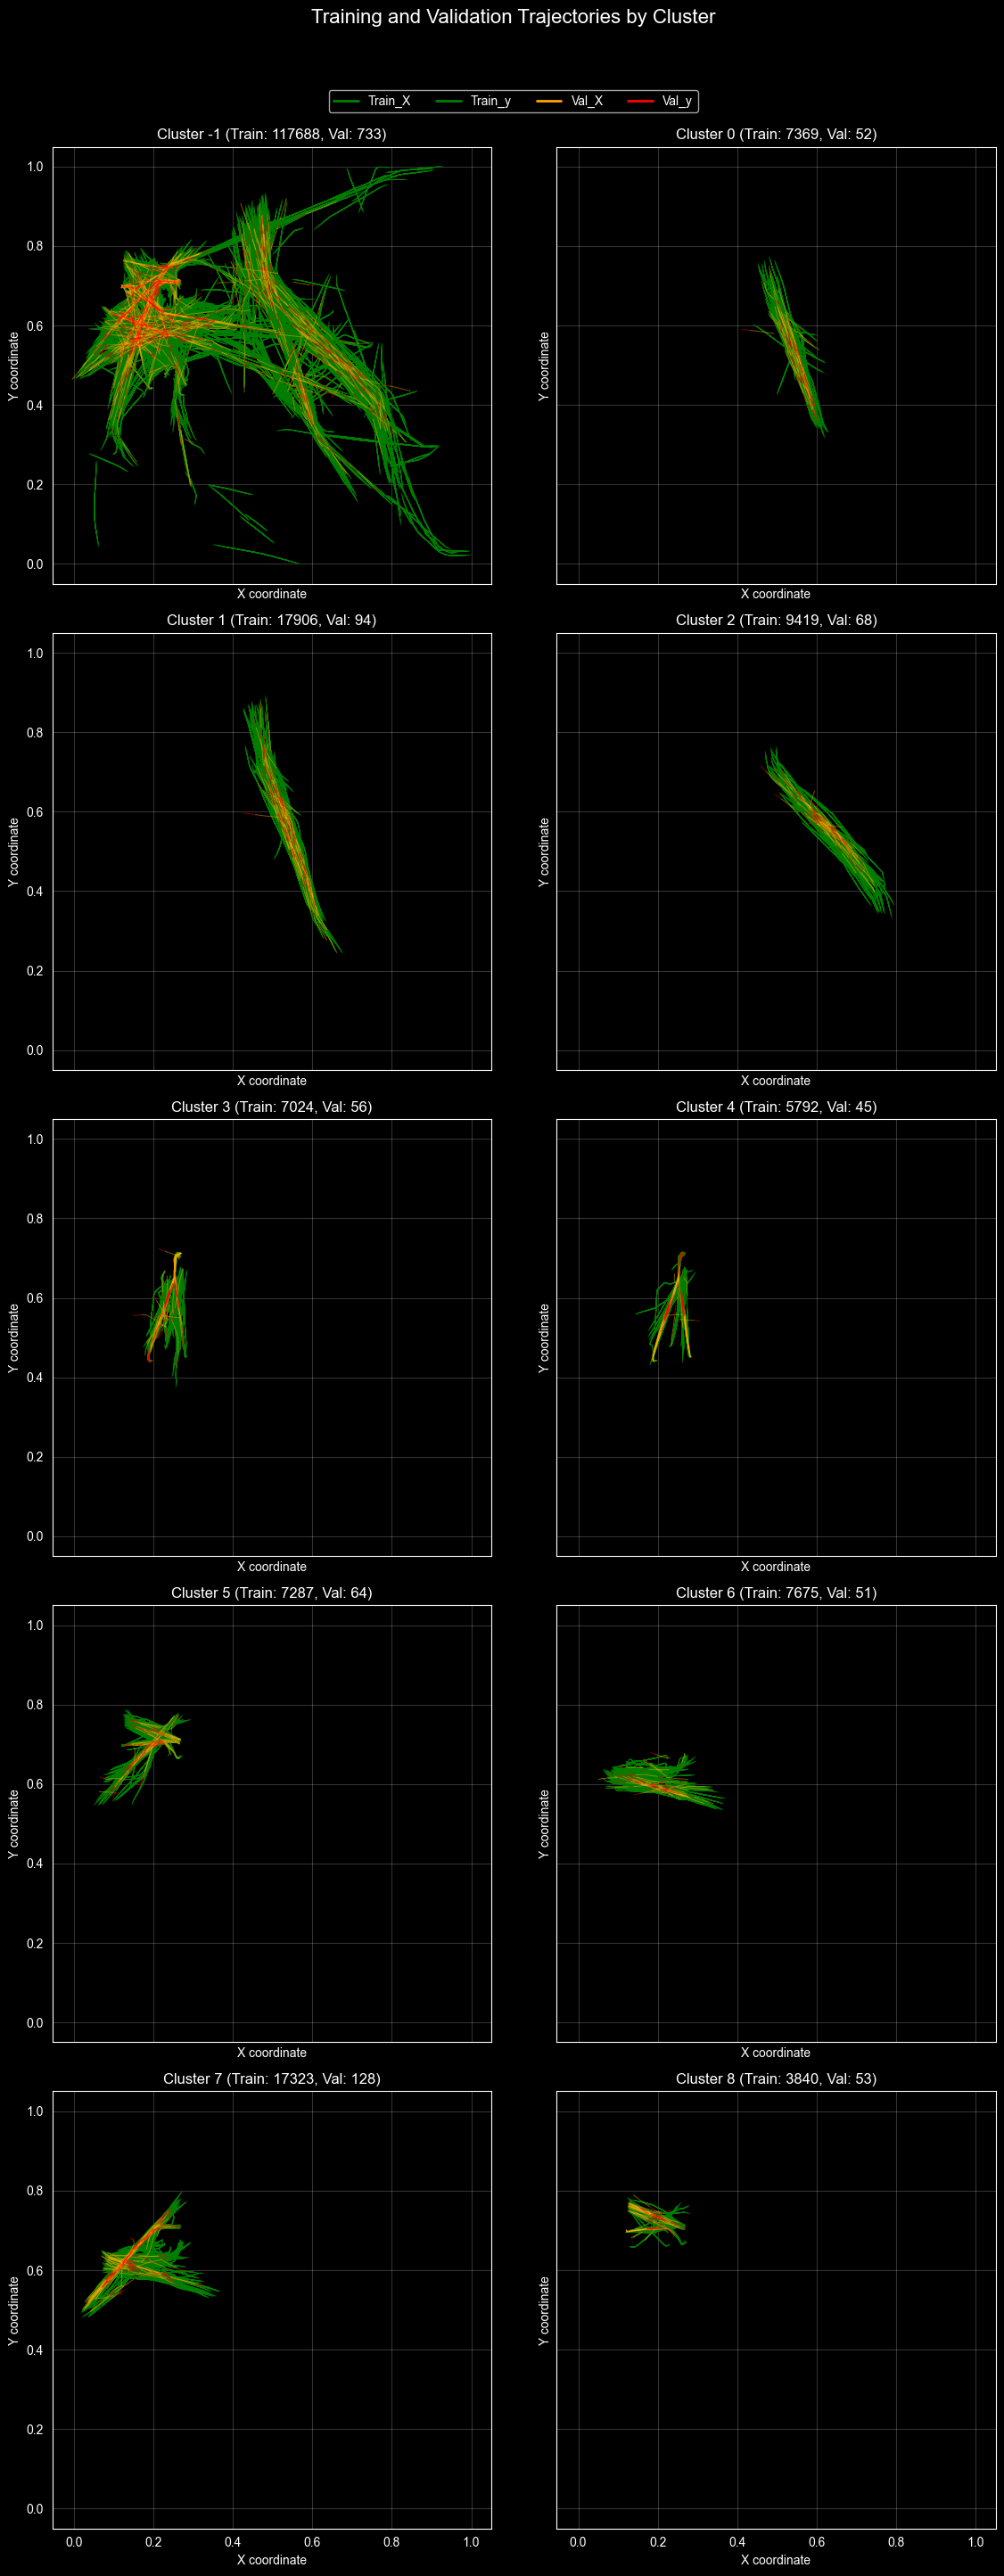

In [17]:
# Noise group + 9 clusters
cluster_labels = [-1, 0, 1, 2, 3, 4, 5, 6, 7, 8]

# Colors for the four datasets
colors = {
    "Train_X": "green",
    "Train_y": "green",
    "Val_X": "orange",
    "Val_y": "red"
}

fig, axes = plt.subplots(
    5, 2,
    figsize=(12,28),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, cluster in zip(axes, cluster_labels):

    # Retrieve trajectories for this cluster
    datasets = {
        "Train_X": Train_X[cluster],
        "Train_y": Train_y[cluster],
        "Val_X": Val_X[cluster],
        "Val_y": Val_y[cluster]
    }

    # Plot every trajectory in each dataset
    for name, trajectories in datasets.items():

        for traj in trajectories:
            traj = np.asarray(traj)

            ax.plot(
                traj[:, 0],
                traj[:, 1],
                color=colors[name],
                linewidth=0.7,
                alpha=0.5
            )

    ax.set_title(
        f"Cluster {cluster} "
        f"(Train: {len(Train_X[cluster])}, "
        f"Val: {len(Val_X[cluster])})"
    )

    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.2)

# One shared legend for the entire figure
legend_handles = [
   Line2D([0], [0], color=colors[name], lw=2, label=name)
   for name in colors]

fig.legend(handles=legend_handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.0))

fig.suptitle(
    "Training and Validation Trajectories by Cluster",
    fontsize=16,
    y=1.03
)

plt.tight_layout()
plt.show()

# LSTM model training

In [20]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [21]:
# Reproducibility
tf.keras.utils.set_random_seed(42)

# Model dimensions
n_features = len(features)       # 5
n_targets = len(target_features) # 2

model = keras.Sequential([
    keras.Input(shape=(input_steps, n_features)),

    layers.LSTM(64,return_sequences=False),

    layers.Dropout(0.1),

    layers.Dense(64,activation="relu"),

    # Predict 10 steps × 2 coordinates
    layers.Dense(output_steps * n_targets),

    # Reshape output into (10, 2)
    layers.Reshape((output_steps, n_targets))
])

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 10, 2)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,380 (91.33 KB)

 Trainable params: 23,380 (91.33 KB)

 Non-trainable params: 0 (0.00 B)

We will use early stopping so that training can stop when validation performance no longer improves.

In [22]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        "lstm_cluster1_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [27]:
training_clustered

,cluster,UTC,trajectory_ID,MMSI,TIMESTAMP,LON,LAT,SOG,COG,STATUS,STATUS_DESC,index,LON_meters,LAT_meters,X,Y,COG_sin,COG_cos
0,-1,2024-08-02 10:51:57+00:00,7,200134975,1722595917,24.824017,37.313967,NaN,NaN,0,Under way using engine,2024-08-02 10:51:57+00:00,307176.119589,4.131923e+06,0.074168,0.630999,NaN,NaN
1,-1,2024-08-02 10:52:57+00:00,7,200134975,1722595977,24.826572,37.313311,0.256991,107.889077,0,Under way using engine,2024-08-02 10:52:57+00:00,307400.933385,4.131845e+06,0.075145,0.630568,0.951653,-0.307175
2,-1,2024-08-02 10:53:57+00:00,7,200134975,1722596037,24.829128,37.312654,0.256993,107.888931,0,Under way using engine,2024-08-02 10:53:57+00:00,307625.751048,4.131767e+06,0.076123,0.630137,0.951654,-0.307173
3,-1,2024-08-02 10:54:57+00:00,7,200134975,1722596097,24.831683,37.311998,0.256995,107.888785,0,Under way using engine,2024-08-02 10:54:57+00:00,307850.572578,4.131689e+06,0.077101,0.629706,0.951655,-0.307170
4,-1,2024-08-02 10:55:57+00:00,7,200134975,1722596157,24.834309,37.311290,0.265465,108.734493,0,Under way using engine,2024-08-02 10:55:57+00:00,308081.518142,4.131605e+06,0.078106,0.629242,0.947017,-0.321183
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
305373,-1,2024-07-23 13:11:55+00:00,46256,799798897,1721740315,25.966699,37.125111,0.398183,130.770848,0,Under way using engine,2024-07-23 13:11:55+00:00,408210.470840,4.109251e+06,0.513611,0.505692,0.757327,-0.653035
305374,-1,2024-07-23 13:12:55+00:00,46256,799798897,1721740375,25.969767,37.123215,0.373444,127.786195,0,Under way using engine,2024-07-23 13:12:55+00:00,408480.661436,4.109038e+06,0.514786,0.504513,0.790303,-0.612717
305375,-1,2024-07-23 13:13:55+00:00,46256,799798897,1721740435,25.972848,37.121200,0.383548,129.352537,0,Under way using engine,2024-07-23 13:13:55+00:00,408752.006166,4.108811e+06,0.515966,0.503261,0.773259,-0.634090
305376,-1,2024-07-23 13:14:55+00:00,46256,799798897,1721740495,25.975932,37.119200,0.382527,129.126869,0,Under way using engine,2024-07-23 13:14:55+00:00,409023.531475,4.108586e+06,0.517147,0.502018,0.775751,-0.631040


In [23]:
history = model.fit(
    Train_X[1],
    Train_y[1],

    validation_data=(Val_X[1], Val_y[1]),

    epochs=100,
    batch_size=64,

    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

Epoch 1/100
277/280 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3077 - mae: 0.5484
Epoch 1: val_loss improved from None to 0.28722, saving model to lstm_cluster1_best.keras
280/280 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.3001 - mae: 0.5415 - val_loss: 0.2872 - val_mae: 0.5282 - learning_rate: 1.0000e-04
Epoch 2/100
275/280 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2785 - mae: 0.5213
Epoch 2: val_loss improved from 0.28722 to 0.25939, saving model to lstm_cluster1_best.keras
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2712 - mae: 0.5142 - val_loss: 0.2594 - val_mae: 0.5011 - learning_rate: 1.0000e-04
Epoch 3/100
276/280 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2512 - mae: 0.4944
Epoch 3: val_loss improved from 0.25939 to 0.23362, saving model to lstm_cluster1_best.keras
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2444 - mae: 0.4875 - val_loss: 0.2336 - val_mae: 0.4747 - learning_rate: 1.0000e-04
Epoch 4/100
276/280 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2259 - ma

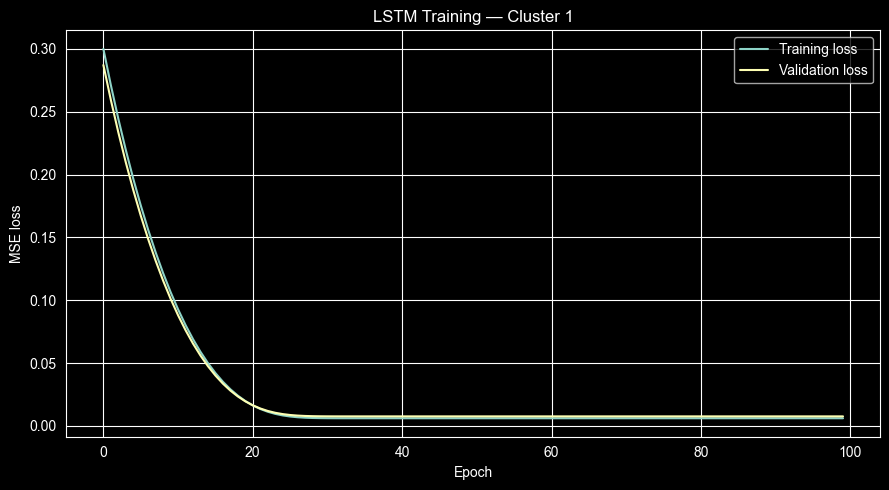

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("LSTM Training — Cluster 1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
from pyproj import Transformer
tf = Transformer.from_crs("EPSG:4326", "EPSG:32635", always_xy=True)  # zone 35N covers 24-30°E
x, y = tf.transform(training['LON'].values, training['LAT'].values)
training['LON_meters'] = x
training['LAT_meters'] = y

In [27]:
print(training_clustered["LON_meters"].max(), training_clustered["LON_meters"].min(),training_clustered["LAT_meters"].max(), training_clustered["LAT_meters"].min())

520038.3175871553 290123.9341037078 4191431.732383379 4038664.486777589


In [28]:
print(training["LON_meters"].max(), training["LON_meters"].min(),training["LAT_meters"].max(), training["LAT_meters"].min())

520038.3175871553 290123.9341037078 4191431.732383379 4038664.486777589


In [29]:
from sklearn.preprocessing import MinMaxScaler
xy_scaler = MinMaxScaler()
xy_scaler.fit(training_clustered[["LON_meters","LAT_meters"]])

,feature_range,"(0, ...)"
,copy,True
,clip,False


In [30]:
Val_y[1]

array([[[0.630404  , 0.30191055],
        [0.62938637, 0.30372834],
        [0.6283619 , 0.30555427],
        ...,
        [0.6230632 , 0.31455368],
        [0.6219678 , 0.31629503],
        [0.62091726, 0.3180119 ]],

       [[0.5986666 , 0.3789071 ],
        [0.5980788 , 0.3810229 ],
        [0.5975143 , 0.3831435 ],
        ...,
        [0.59483236, 0.39385536],
        [0.59429544, 0.39601493],
        [0.59373385, 0.39811963]],

       [[0.57374763, 0.46443573],
        [0.57306   , 0.46657905],
        [0.57238275, 0.46872953],
        ...,
        [0.5691598 , 0.47958013],
        [0.56856215, 0.48173544],
        [0.5679399 , 0.483955  ]],

       ...,

       [[0.49879727, 0.6802647 ],
        [0.49761027, 0.6820901 ],
        [0.49638295, 0.68386686],
        ...,
        [0.48999283, 0.6926064 ],
        [0.48874107, 0.6944435 ],
        [0.48753357, 0.69632065]],

       [[0.539503  , 0.52684045],
        [0.53848976, 0.529836  ],
        [0.537493  , 0.5328517 ],
        .

In [31]:
# Predict all 10 future positions for each validation window
y_pred = model.predict(Val_X[1])
# Euclidean distance at each future time step
displacement = np.linalg.norm(
    y_pred - Val_y[1],
    axis=2
)

ADE_normalized = displacement.mean()

FDE_normalized = displacement[:, -1].mean()

print("ADE (normalized units):", ADE_normalized)
print("FDE (normalized units):", FDE_normalized)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
ADE (normalized units): 0.100760475
FDE (normalized units): 0.10063371


In [33]:
# scaler_xy must be the SAME fitted scaler
# that was used to normalize the X and Y coordinates.

def inverse_xy(values, xy_scaler):
    original_shape = values.shape

    restored = xy_scaler.inverse_transform(
        values.reshape(-1, 2)
    )

    return restored.reshape(original_shape)


y_pred_m = inverse_xy(y_pred, xy_scaler)
y_val_m = inverse_xy(Val_y[1], xy_scaler)

displacement_m = np.linalg.norm(
    y_pred_m - y_val_m,
    axis=2
)

ADE_m = displacement_m.mean()
FDE_m = displacement_m[:, -1].mean()

print(f"ADE: {ADE_m:.2f} meters")
print(f"FDE: {FDE_m:.2f} meters")

ADE: 16510.86 meters
FDE: 16508.91 meters


In [34]:
X_val_m = inverse_xy(Val_X[1][:, 0:2], xy_scaler)

In [35]:
training_clustered[training_clustered["cluster"]==1][["LON_meters", "LAT_meters"]]

,LON_meters,LAT_meters
507,411319.944431,4.138057e+06
508,410980.134518,4.138268e+06
509,410637.961114,4.138477e+06
510,410297.470097,4.138688e+06
511,409959.970941,4.138906e+06
...,...,...
303901,404204.892354,4.136943e+06
303902,404026.857554,4.137248e+06
303903,403852.016441,4.137547e+06
303904,403676.360422,4.137851e+06


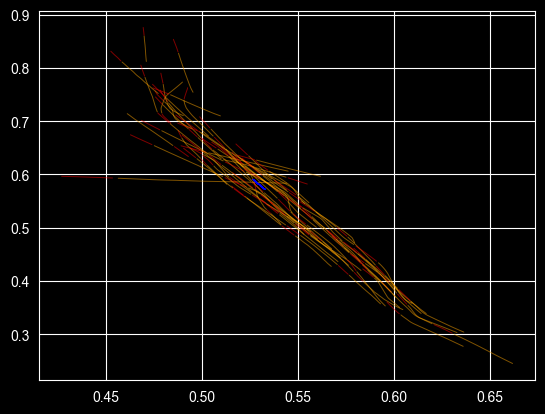

In [37]:
df_Val_X = Val_X[1]
df_Val_y = Val_y[1]

n = len(df_Val_X)
# Generate colors
colors = plt.cm.tab20(np.linspace(0, 1, n))
for i, color in zip(range(n), colors):
    plt.plot(df_Val_X[i][:,0],
             df_Val_X[i][:,1],
             color="orange", linewidth=0.7, alpha=0.5)
    plt.plot(df_Val_y[i][:,0],
             df_Val_y[i][:,1],
             color="red", linewidth=0.7, alpha=0.5)
    plt.plot(y_pred[i][:,0],
             y_pred[i][:,1],
             color = "blue", linewidth=0.7, alpha=0.5)

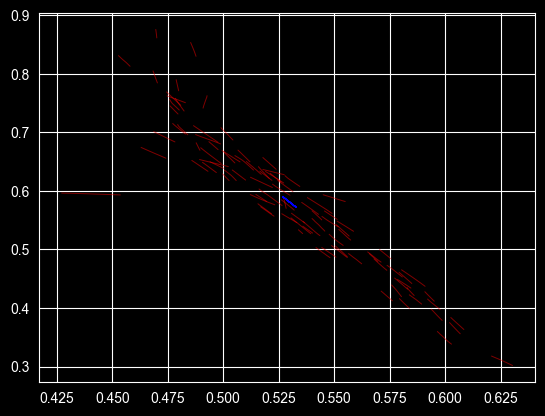

In [38]:
df_Val_X = Val_X[1]
df_Val_y = Val_y[1]

n = len(df_Val_X)
# Generate colors
colors = plt.cm.tab20(np.linspace(0, 1, n))
for i, color in zip(range(n), colors):
    plt.plot(df_Val_y[i][:,0],
         df_Val_y[i][:,1],
         color="red", linewidth=0.7, alpha=0.5)

    plt.plot(y_pred[i][:,0],
             y_pred[i][:,1],
             color = "blue", linewidth=0.7, alpha=0.5)